In [1]:
from collections import defaultdict, deque
from math import log2
import re
import heapq
import gc
from wordcloud import WordCloud
import matplotlib.pyplot as plt

In [2]:
with open("/kaggle/input/datasets/yunuskedir/gpac-corpus/GPAC.txt") as f:
    text = f.read()
text = text[:len(text) // 10]
print(f"Corpus is {len(text)} characters long.")

Corpus is 42439773 characters long.


In [3]:
### Preprocessing functions

def normalize_phonetically_similar_characters(text):
    print("Normalizing phonetically similar characters in the Amharic Langauge (ሐ -> ሀ, ኀ -> ሀ, ሠ -> ሰ, ፀ -> ጸ)...")
    replacement_map = {
      "ሐሑሒሓሔሕሖ": "ሀሁሂሃሄህሆ",
      "ኀኁኂኃኄኅኆ": "ሀሁሂሃሄህሆ",
      "ሠሡሢሣሤሥሦሧ": "ሰሱሲሳሴስሶሷ",
      "ፀፁፂፃፄፅፆ": "ጸጹጺጻጼጽጾ"
    }
    for chars, replacements in replacement_map.items():
        for i in range(len(chars)):
            text = text.replace(chars[i], replacements[i])
    return text

def remove_common_stopwords(text):
    print("Removing common stopwords...")
    stopwords = ["ነው", "አይደለም", "ነበር", "ነበረ", "አልነበረም", "ሆነ", "አልሆነም", "ይሆናል", "አይሆንም"]
    for word in stopwords:
        text = re.sub(rf"\s+{word}\s*", " ", text)
    return text

def remove_extra_whitespace(text):
    print("Removing any extra whitespace between words...")
    return re.sub(r"\s+", " ", text)

def remove_punctuation(text):
    print("Removing punctuation to decrease noise...")
    punctuations = ["፣", "፤", "(", ")", "፦", "፡"]
    for punc in punctuations:
        text = text.replace(punc, "")
    return text

def add_delimiter_tags(text):
    print("Adding sentence delimiter tags (<s></s>)...")
    text = "<s> " + text
    sentence_delimiters = ["፡፡", "።", "!", "?"]
    for delimiter in sentence_delimiters:
        text = text.replace(delimiter, f" {delimiter} </s> ")
    
    text = " ".join(text.split())
    
    if text.endswith("<s>"):
        text = text[:-3].strip()

    return text

def remove_sentence_delimiters(text):
    print("Removing common sentence delimiters...")
    sentence_delimiters = ["፡፡", "።", "!", "?"]
    for delimiter in sentence_delimiters:
        text = text.replace(delimiter, "")
    return text

def preprocess_corpus(corpus_content: str, remove_stopwords: bool = False, remove_sentence_delims: bool = False):
    print("Initialzing corpus preprocessing...")
    print("Trimming any extra whitespace...")
    corpus_content = corpus_content.strip()
    corpus_content = normalize_phonetically_similar_characters(corpus_content)
    if remove_sentence_delims:
        corpus_content = remove_sentence_delimiters(corpus_content)
    else:
        corpus_content = add_delimiter_tags(corpus_content)
    corpus_content = remove_extra_whitespace(corpus_content)
    corpus_content = remove_punctuation(corpus_content)
    if remove_stopwords:
        corpus_content = remove_common_stopwords(corpus_content)
    print("Preprocessing finished...")
    return corpus_content

In [4]:
def get_corpus_words(corpus):
    words = corpus.split()
    return words

In [5]:
sanitized_corpus = preprocess_corpus(text, remove_stopwords=True)
del text
corpus_words = get_corpus_words(sanitized_corpus)
print(f"Corpus contains {len(corpus_words)} words, and {len(set(corpus_words))} unique words.")
del sanitized_corpus
gc.collect()
split_idx = int(len(corpus_words) * 0.8)
train_data = corpus_words[:split_idx]
test_data = corpus_words[split_idx:]

Initialzing corpus preprocessing...
Trimming any extra whitespace...
Normalizing phonetically similar characters in the Amharic Langauge (ሐ -> ሀ, ኀ -> ሀ, ሠ -> ሰ, ፀ -> ጸ)...
Adding sentence delimiter tags (<s></s>)...
Removing any extra whitespace between words...
Removing punctuation to decrease noise...
Removing common stopwords...
Preprocessing finished...
Corpus contains 8555682 words, and 621184 unique words.


In [6]:
class MaxNGramModel:
    def __init__(self, words: list[str], max_n: int = 4):
        if max_n < 1 or max_n > 4:
            raise ValueError(f"max_n must be a value between 1 and 4: {max_n} was given.")
        print(f"Initializing MaxNGramModel instance of max order {max_n}...")
        self.max_n = max_n
        self.ngram_counts = { i: defaultdict(int) for i in range(1, self.max_n + 1) }
        self.__build_counts(words)
        self.unigrams_total = sum(self.ngram_counts[1].values())
        del words
        print("Finished initializing MaxNGramModel instance. Model is ready to use.")

    def __build_counts(self, words: list[str]):
        window = deque(maxlen=self.max_n)
        for i in range(len(words)):
            word = words[i]
            if word == "</s>":
                window.clear()
                continue
            window.append(word)
            for j in range(1, len(window) + 1):
                ngram_tuple = tuple(list(window)[-j:])
                self.ngram_counts[j][ngram_tuple] += 1

    def get_k_most_frequent_sequences(self, n: int, k: int = 10):
        if n > self.max_n:
            print(f"n cannot be greater than {self.max_n}. Using n={self.max_n} instead.")
            n = self.max_n
        top_tuples = heapq.nlargest(k, self.ngram_counts[n], key=lambda x: self.ngram_counts[n][x])
        return [(" ".join(t), self.ngram_counts[n][t]) for t in top_tuples]

    def get_word_probability(self, word: str, n: int = 2, history: str = "", prefix=""):
        if not word:
            print("Please provide a non-empty word.")
            return None
        if n > self.max_n:
            print(f"n cannot be greater than {self.max_n}. Using n={self.max_n} instead.")
            n = self.max_n

        history_words = tuple(history.split()[-n + 1:])
        if len(history_words) < n - 1:
            print(f"For order n={n}, history must contain at least {n-1} words. {len(history_words)} words given, using n={len(history_words) + 1} instead.")
            n = len(history_words) + 1
        
        while n > 1:
            history_words = history_words[-n+1:]
            if self.ngram_counts[n-1].get(history_words, 0) == 0:
                print(f"'{" ".join(history_words)}' not found in the corpus. Trying with less words.")
                n -= 1
            else:
                break

        if n == 1:
            history_words = tuple()
        if prefix:
            valid_sequences = { t: count for t, count in self.ngram_counts[n].items() if t[:-1] == history_words and t[-1].startswith(prefix) }
            count_history = sum(valid_sequences.values())
            count_together = valid_sequences.get(history_words + (word,), 0)
        else:
            count_history = self.ngram_counts[n-1].get(history_words, 0) if n > 1 else self.unigrams_total
            count_together = self.ngram_counts[n].get(history_words + (word,), 0)
        if count_history == 0:
            return 0.0
        return count_together / count_history

    def get_k_most_probable_words(self, n: int = 1, history: str = "", prefix: str = "", k: int = 10):
        if n > self.max_n:
            print(f"n cannot be greater than {self.max_n}. Using n={self.max_n} instead.")
            n = self.max_n
        history_words = tuple(history.split()[-n+1:])
        if len(history_words) < n - 1:
            print(f"For order n={n}, history must contain at least {n - 1} words. {len(history_words)} words given, using n={len(history_words) + 1} instead.")
            n = len(history_words) + 1
        
        while n > 1:
            history_words = history_words[-n+1:]
            if self.ngram_counts[n-1].get(history_words, 0) == 0:
                print(f"'{" ".join(history_words)}' not found in the corpus. Trying with less words.")
                n -= 1
            else:
                break
        if n == 1:
            history_words = tuple()
        valid_sequences = { t: count for t, count in self.ngram_counts[n].items() if t[:-1] == history_words and t[-1].startswith(prefix) }
        count_history = sum(valid_sequences.values())
        if count_history == 0:
            return []
        top_tuples = heapq.nlargest(k, valid_sequences, key=lambda x: valid_sequences[x])
        return [(t[-1], valid_sequences[t] / count_history) for t in top_tuples]        

    def draw_wordcloud(self, n: int = 1, title: str = ""):
        if n > self.max_n:
            print(f"n cannot be greater than {self.max_n}. Using n={self.max_n} instead.")
            n = self.max_n
        freq_dict = { " ".join(t): count for t, count in self.ngram_counts[n].items() }

        wc = WordCloud(
            width=800,
            height=400,
            background_color="white",
            font_path="/kaggle/input/datasets/yunuskedir/hiburmono-font/HiburMono-Regular.ttf"
        ).generate_from_frequencies(freq_dict)

        plt.figure(figsize=(12, 6))
        plt.imshow(wc, interpolation="bilinear")
        plt.axis("off")
        plt.title(title if title else f"Word Cloud for NGram of order {n}")
        plt.show()

    def calculate_perplexity(self, n: int, test_data: list[str]):
        log_prob_sum = 0
        count = 0
        for i in range(n - 1, len(test_data)):
            sequence = test_data[i-n+1:i+1]
            if "</s>" in sequence:
                i += sequence.index("</s>")
                continue
            if n == 1 or self.ngram_counts[n-1][tuple(sequence[:-1])]:
                history = " ".join(sequence[:-1])
                prob = self.get_word_probability(sequence[-1], n, history)
                if prob > 0:
                    log_prob_sum += log2(prob)
                count += 1
        return 2 ** (-1 * (log_prob_sum / count))

    def calculate_accuracy(self, n: int, test_data: list[str]):
        count = 0
        correct_count = 0
        for i in range(n-1, len(test_data)):
            sequence = test_data[i-n+1:i+1]
            if "</s>" in sequence:
                i += sequence.index("</s>")
                continue
            context = " ".join(sequence[:-1])
            correct_word = sequence[-1]
            top_10_predictions = self.get_k_most_probable_words(n, history=context)
            top_10_words = list(map(lambda t: t[0], top_10_predictions))
            if correct_word in top_10_words:
                correct_count += (10 - top_10_words.index(correct_word)) / 10
            count += 1
        return (correct_count/(count if count else 1)) * 100
            

In [7]:
max_4_gram = MaxNGramModel(corpus_words, max_n=4)

Initializing MaxNGramModel instance of max order 4...
Finished initializing MaxNGramModel instance. Model is ready to use.


# **Top 10 most frequent sequences/words**

In [8]:
for i in range(1, 5):
    top_sequences = max_4_gram.get_k_most_frequent_sequences(n=i)
    print(f"N={i} most frequent sequences/words")

    for sequence in top_sequences:
        print(f"\t{sequence[0]} -> Counted {sequence[1]} times.")

N=1 most frequent sequences/words
	። -> Counted 84446 times.
	ላይ -> Counted 75143 times.
	? -> Counted 54129 times.
	! -> Counted 52228 times.
	ወደ -> Counted 36096 times.
	ውስጥ -> Counted 36037 times.
	ግን -> Counted 35935 times.
	እና -> Counted 31101 times.
	ነገር -> Counted 28990 times.
	ጋር -> Counted 28632 times.
N=2 most frequent sequences/words
	ዓ ም -> Counted 7289 times.
	ነገር ግን -> Counted 5121 times.
	ብቻ ሳይሆን -> Counted 3474 times.
	አዲስ አበባ -> Counted 2638 times.
	በአዲስ አበባ -> Counted 2158 times.
	በሌላ በኩል -> Counted 2074 times.
	ምን ያህል -> Counted 2068 times.
	ናቸው ። -> Counted 1862 times.
	እንዴ ? -> Counted 1699 times.
	እ ኤ -> Counted 1602 times.
N=3 most frequent sequences/words
	እ ኤ አ -> Counted 1573 times.
	ቂ ቂ ቂ -> Counted 642 times.
	የኢትዮጵያ ብሄራዊ ቡድን -> Counted 449 times.
	ወደ አዲስ አበባ -> Counted 441 times.
	ምን ይመስላል ? -> Counted 368 times.
	ከጊዜ ወደ ጊዜ -> Counted 367 times.
	የአዲስ አድማስ ጋዜጠኛ -> Counted 364 times.
	እንግዲህ ጨዋታም አይደል -> Counted 360 times.
	በሌላ በኩል ደግሞ -> Counted 355 times.
	

# **Wordclouds**

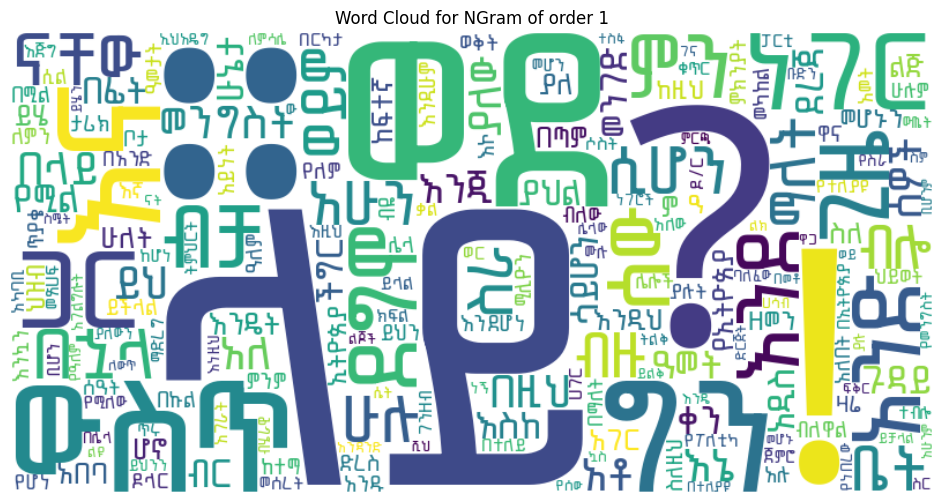

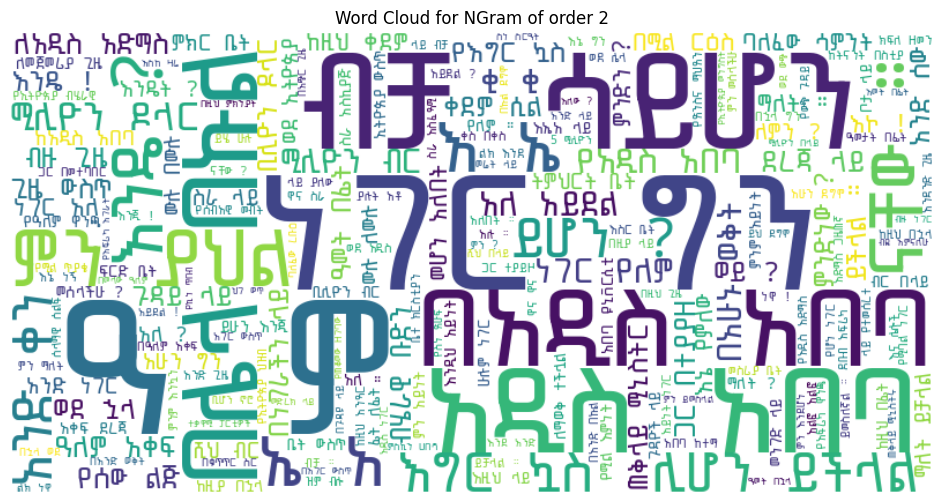

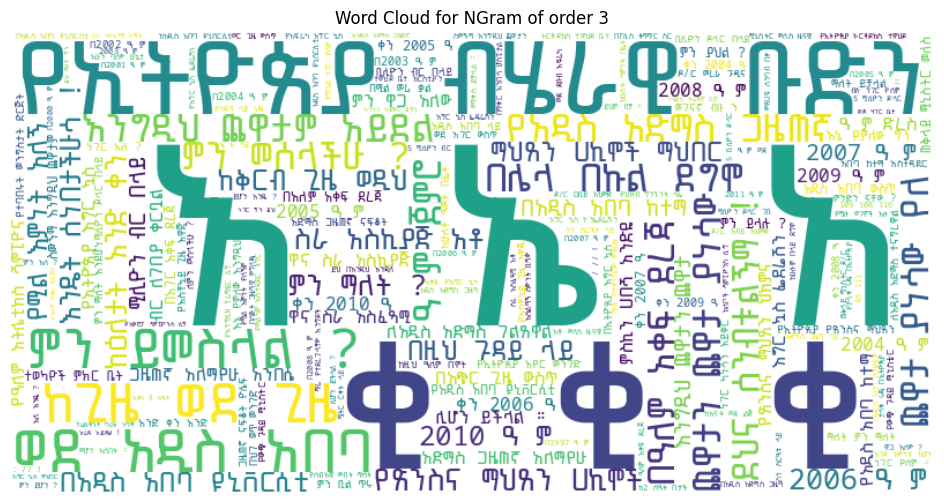

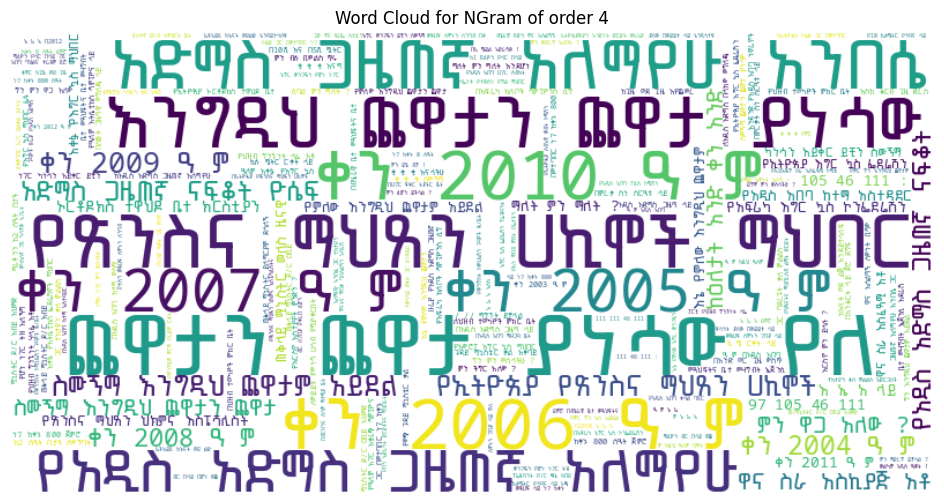

In [9]:
for i in range(1, 5):
    max_4_gram.draw_wordcloud(i)

# **Sentence Generation**

In [10]:
def generate_sentence(model: MaxNGramModel, n: int, sentence: str = "", k: int = 10):
    for i in range(k):
        top_suggestion = model.get_k_most_probable_words(n, sentence, k=1)
        if top_suggestion:
            sentence = sentence + " " + top_suggestion[0][0]

    return sentence


for i in range(1, 5):
    print(f"*** Sentence Generated By {i}-Gram ***")
    sentence = "የተጐናጸፉ ሰዎች የህይወት ታሪክ"
    result = generate_sentence(max_4_gram, i, sentence, 10)
    print(result)
    print()

*** Sentence Generated By 1-Gram ***
የተጐናጸፉ ሰዎች የህይወት ታሪክ ። ። ። ። ። ። ። ። ። ።

*** Sentence Generated By 2-Gram ***
የተጐናጸፉ ሰዎች የህይወት ታሪክ ውስጥ ያለው ሰው ሁሉ ነገር ግን ምን ያህል ጊዜ ውስጥ

*** Sentence Generated By 3-Gram ***
የተጐናጸፉ ሰዎች የህይወት ታሪክ መጽሀፍ ውስጥ ስለ ኢትዮጵያ ታሪክ በሚለው መጽሀፋቸው ውስጥ ጥቂቱ ክፍል

*** Sentence Generated By 4-Gram ***
የተጐናጸፉ ሰዎች የህይወት ታሪክ መመርመር ያሉት ደግሞ በጠቅላይ ሚኒስቴር ሚኒስትር የኢትዮጵያ ፉትቦል ፌዴሬሽን አንደኛ



In [11]:
del max_4_gram

# **Intrinsic Evaluation (Perplexity) of N-Grams**

***This model has a mechanism to fallback to lower n grams for sequences which couldn't be found in the counts. Therefore, the perplexity and accuracy measurements are distorted. They are only presented here for experimentation, and to display the general trend as n grows; not as accurate representations of n-grams evaluation***

Initializing MaxNGramModel instance of max order 4...
Finished initializing MaxNGramModel instance. Model is ready to use.
{1: 10155.66242627368, 2: 7.208792606046331, 3: 1.4969189215249123, 4: 1.1901702663479945}


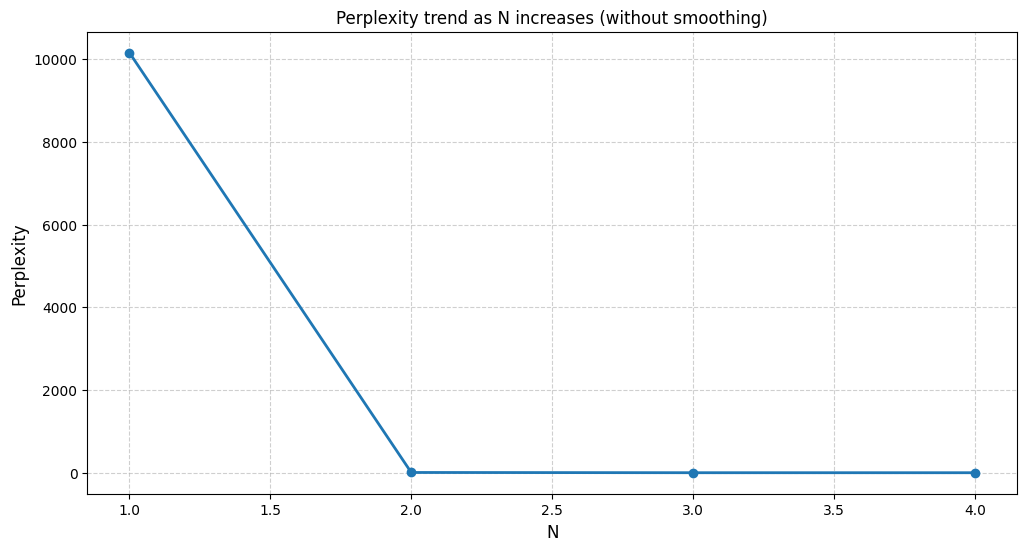

In [12]:
trained_max_4_gram = MaxNGramModel(train_data, max_n=4)

perplexity_dict = {}

for i in range(1, 5):
    perplexity = trained_max_4_gram.calculate_perplexity(i, test_data[-1000000:])
    perplexity_dict[i] = perplexity
print(perplexity_dict)
plt.figure(figsize=(12, 6))
plt.plot(perplexity_dict.keys(), perplexity_dict.values(), linestyle="-", linewidth=2, marker="o")
plt.title("Perplexity trend as N increases (without smoothing)")
plt.xlabel("N", fontsize=12)
plt.ylabel("Perplexity", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()

# **Extrinsic Evaluation (Accuracy) of N-Grams**

'ማዘጋጀትየፈተና' not found in the corpus. Trying with less words.
'ስነምግባርቀጣይነት' not found in the corpus. Trying with less words.
'መንገድ ደረጃውን' not found in the corpus. Trying with less words.
'ያሟላ ትምህርት' not found in the corpus. Trying with less words.
'በሁሉም ዩኒቨርሲቲዎች' not found in the corpus. Trying with less words.
'መንገድ እንዲሰጥ' not found in the corpus. Trying with less words.
'የ ና' not found in the corpus. Trying with less words.
'የ ትብብር' not found in the corpus. Trying with less words.
'ትብብር ፕሮጀክት' not found in the corpus. Trying with less words.
'ፕሮጀክት በአጠ' not found in the corpus. Trying with less words.
'ቃላይ በስምንት' not found in the corpus. Trying with less words.
'ላይ ይሰራል::' not found in the corpus. Trying with less words.
'ይሰራል:: የማህጸንና' not found in the corpus. Trying with less words.
'ህክምና ልዩ' not found in the corpus. Trying with less words.
'ትምህርት ስርአተ' not found in the corpus. Trying with less words.
'ትምህርት ደረጃውን' not found in the corpus. Trying with less words.
'መንገድ ማዘጋጀትየፈተና' no

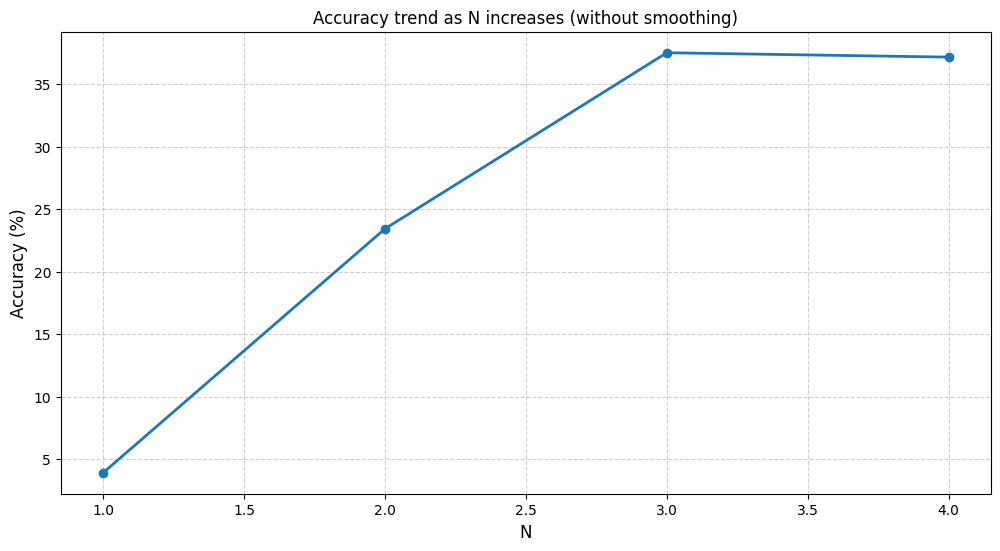

In [13]:
accuracy_dict = {}

for i in range(1, 5):
    accuracy = trained_max_4_gram.calculate_accuracy(i, test_data[-100:])
    accuracy_dict[i] = accuracy
print(accuracy_dict)
plt.figure(figsize=(12, 6))
plt.plot(accuracy_dict.keys(), accuracy_dict.values(), linestyle="-", linewidth=2, marker="o")
plt.title("Accuracy trend as N increases (without smoothing)")
plt.xlabel("N", fontsize=12)
plt.ylabel("Accuracy (%)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()